# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [40]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [41]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [42]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [43]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [44]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [45]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [46]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [47]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [48]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [49]:
# cantidad de nulos para users
print(users.isna().sum())

# Proporción de valores nulos
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [50]:
# cantidad de nulos para usage
print(usage.isna().sum())

# Proporción de valores nulos
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?
- 
Para el Dataframe users podemos evidenciar que el 11.725 % de los registros no tiene ciudad. No eliminaría esas filas porque perderíamos una parte importante de los usuarios. Como es una variable categórica, reemplazaría los nulos por "N/A o No informado" si necesito incluirlos en un análisis por ciudad.
El 88.35 % de los registros no tiene fecha de cancelación. Esto puede indicar que esos usuarios todavía no han cancelado el servicio. Conservaría los nulos como parte del significado de los datos.

Por otro lado el Dataframe usage: 
-date: revisar y, si no se puede recuperar, considerar eliminar las 50 filas. La proporción es muy pequeña (0.125 %). Sin embargo, como la fecha puede ser importante para analizar el uso por mes, no conviene inventar fechas.

-duration: no imputaría todavía. Tiene un 55.19 % de valores faltantes. Primero revisaría si esos valores faltan según el tipo de registro. Si la duración no aplica a algunos tipos de uso, conservaría los nulos; si deberían tener un valor, investigaría la causa antes de imputar.

-length: tampoco imputaría automáticamente. Tiene un 44.74 % de valores faltantes. Revisaría la relación con type para saber si se trata de valores que no aplican o de datos que realmente faltan.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [51]:

# explorar columnas numéricas de users
columnas_numericas = users.select_dtypes(include="number").columns
print(columnas_numericas)



Index(['user_id', 'age'], dtype='object')


Se puede evidenciar que las columnas user_id y age son columnas numericas.

In [52]:
# explorar columnas numéricas de usage
columnas_numericas = usage.select_dtypes(include="number").columns
print(columnas_numericas)


Index(['id', 'user_id', 'duration', 'length'], dtype='object')


Se puede evidenciar que las columnas 'id', 'user_id', 'duration', 'length' son columnas numericas.

In [53]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()


,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` contiene 3531 usuarios tienen una ciudad registrada, hay 7 ciudades diferentes, la mas frecuente es Bogotá y aparece 808 registros con frecuencia Bogotá que tienen ciudad informada.
- La columna `plan` contiene 4000 usuarios tienen un plan registrado, existen 2 planes diferentes, el mas frecuente es el Basico y 2595 usuarios tienen el plan basico.

In [54]:
# explorar columna categórica de usage
usage["type"].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` evidenciamos que existen 22092 registros en mensajes de texto, mientras que en llamadas 17908. Esta información puede servir para analizar los patrones de consumo y comparar el uso según el plan contratado por los usuarios. ✅


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [55]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB


In [56]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


In [57]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`muestra las fechas de registro de los usuarios entre el año 2022 y 2026, se ve que la distribucion de registros es bastante uniforme entre el 2022 y 2026, sin embargo solo aparecen 40 registros a 2026

In [58]:

# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

In [59]:
# Revisar la cantidad de fechas nulas
print(usage["date"].isna().sum())

# Revisar la proporción de fechas nulas
print(usage["date"].isna().mean())

50
0.00125


En `date`, la columna contiene registros únicamente del año 2024 para las fechas válidas. De los 40.000 registros, 39.950 tienen una fecha registrada y 50 presentan valores faltantes, lo que representa solo el 0,125 %. Se recomienda conservar las fechas válidas y revisar los registros sin fecha, ya que son importantes para analizar el uso del servicio a lo largo del tiempo.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
La columna date contiene registros únicamente del año 2024 para las fechas válidas. De los 40.000 registros, 39.950 tienen una fecha registrada y 50 presentan valores faltantes, lo que representa solo el 0,125 %. Se recomienda conservar las fechas válidas y revisar los registros sin fecha, ya que son importantes para analizar el uso del servicio a lo largo del tiempo.

El valor 2024.0 aparece con decimal porque existen fechas faltantes (NaT); esto no significa que el año esté incorrecto.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [60]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users["age"] != -999, "age"].median()
users["age"] = users["age"].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [61]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)

# Verificar cambios
print(users["city"].isna().sum())
print(users["city"].value_counts(dropna=False))

565
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [62]:

# Marcar fechas futuras como NA para reg_date
users["reg_date"] = pd.to_datetime(users["reg_date"], errors="coerce")

fecha_actual = pd.Timestamp.today().normalize()
users.loc[users["reg_date"] > fecha_actual, "reg_date"] = pd.NaT

# Verificar cambios
print("Fechas nulas:", users["reg_date"].isna().sum())
print(users[users["reg_date"].isna()])

Fechas nulas: 0
Empty DataFrame
Columns: [user_id, first_name, last_name, age, city, reg_date, plan, churn_date]
Index: []


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [63]:

# Verificación MAR en usage (Missing At Random) para duration
# Porcentaje de valores faltantes por tipo de uso
missing_duration_by_type = (
    usage.groupby("type")["duration"]
    .apply(lambda x: x.isna().mean() * 100)
)

print("Porcentaje de duration faltante por tipo:")
print(missing_duration_by_type)


Porcentaje de duration faltante por tipo:
type
call     0.000000
text    99.927576
Name: duration, dtype: float64


In [64]:
# Verificación MAR en usage (Missing At Random) para length
# Verificación MAR en usage para length

# Porcentaje de valores faltantes por tipo de uso
missing_length_by_type = (
    usage.groupby("type")["length"]
    .apply(lambda x: x.isna().mean() * 100)
)

print("Porcentaje de length faltante por tipo:")
print(missing_length_by_type)

Porcentaje de length faltante por tipo:
type
call    99.932991
text     0.000000
Name: length, dtype: float64


In [65]:
# Contar valores faltantes en duration y length
print("Nulos en duration:", usage["duration"].isna().sum())
print("Nulos en length:", usage["length"].isna().sum())

Nulos en duration: 22076
Nulos en length: 17896


In [67]:
# Verificar los valores nulos de duration y length por tipo de uso
resumen_nulos = usage.groupby("type").agg(
    registros=("type", "size"),
    duration_nulos=("duration", lambda x: x.isna().sum()),
    duration_pct=("duration", lambda x: x.isna().mean() * 100),
    length_nulos=("length", lambda x: x.isna().sum()),
    length_pct=("length", lambda x: x.isna().mean() * 100)
)

print(resumen_nulos.round(2))

      registros  duration_nulos  duration_pct  length_nulos  length_pct
type                                                                   
call      17908             0.0          0.00       17896.0       99.93
text      22092         22076.0         99.93           0.0        0.00


Diagnóstico de valores nulos en duration y length:
La tabla muestra un patrón muy claro relacionado con la columna type:
- duration: en las llamadas (call) no hay valores faltantes (0 %), mientras que en los mensajes de texto (text) falta el 99,93 %.
- length: en los mensajes de texto (text) no hay valores faltantes (0 %), mientras que en las llamadas (call) falta el 99,93 %.
Esto indica que los valores faltantes están relacionados con el tipo de uso. El patrón parece corresponder principalmente a faltantes estructurales, ya que la duración aplica a las llamadas y la longitud aplica a los mensajes de texto.

Sin embargo, hay pequeñas excepciones: 16 registros de texto tienen duration informado y 12 llamadas tienen length informado. Conviene revisar esos registros para verificar si son casos válidos o posibles inconsistencias.

Decisión de limpieza: no imputaría automáticamente estos valores faltantes. Mantendría los nulos cuando la variable no aplique al tipo de registro y revisaría las excepciones antes de realizar modificaciones.

Conclusión: los datos sugieren faltantes estructurales asociados a type; no es necesario asumir que son errores ni rellenarlos artificialmente

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [68]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum",
    "length": "sum"
}).reset_index()

# Observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration,length
0,10000,7,3,23.70,258.0
1,10001,5,10,33.18,226.0
2,10002,5,2,10.74,225.0


In [69]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "total_texts",
    "is_call": "total_calls",
    "duration": "total_duration",
    "length": "total_length"
})

# Observar resultado
usage_agg.head(3)

,user_id,total_texts,total_calls,total_duration,total_length
0,10000,7,3,23.70,258.0
1,10001,5,10,33.18,226.0
2,10002,5,2,10.74,225.0


In [70]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Mostrar las primeras 5 filas
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,total_texts,total_calls,total_duration,total_length
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,258.0
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,226.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,225.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,530.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,229.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [71]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,total_texts,total_calls,total_duration,total_length
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054,288.128032
std,1154.844867,17.689919,2.358416,2.144238,18.168095,180.906841
min,10000.000000,18.000000,0.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000,184.000000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000,268.000000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000,361.000000
max,13999.000000,79.000000,17.000000,15.000000,155.690000,2028.000000


In [72]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

💡Insights: 
- Distribución relativamente uniforme: las edades están distribuidas de manera bastante equilibrada, con aproximadamente 350 a 440 usuarios por intervalo.
- Mayor concentración: se observan frecuencias más altas alrededor de los 45–47 años y entre los 75–79 años.
- Menor concentración: los intervalos cercanos a los 65–73 años presentan una cantidad ligeramente menor de usuarios.
- Segmentación de marketing: como no se observa una concentración muy marcada en un solo rango de edad, sería útil analizar también los planes contratados y el consumo para diseñar campañas más específicas.
Conclusión: la base de usuarios presenta diversidad de edades, aproximadamente entre los 18 y 79 años.
- La distribución de edades muestra que el servicio atrae a usuarios de diferentes generaciones, sin una preferencia claramente dominante por un rango de edad. Por ello, sería recomendable combinar la edad con el tipo de plan y los patrones de consumo para identificar qué grupos de clientes generan mayor uso y desarrollar estrategias de fidelización más efectivas.

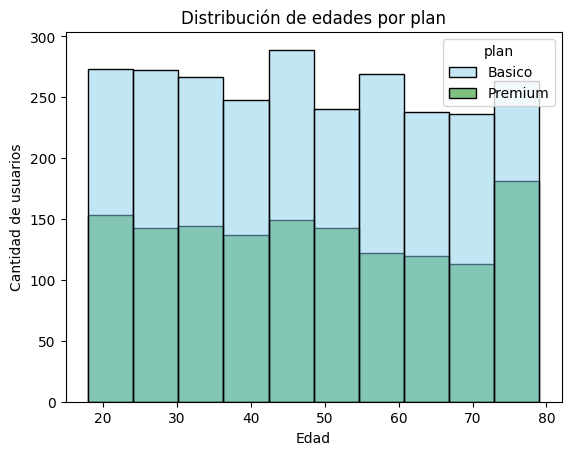

In [73]:
# Histograma para visualizar la edad según el plan
sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    bins=10,
    palette=["skyblue", "green"]
)

plt.title("Distribución de edades por plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: Predominio del plan Básico: se observa una mayor cantidad de usuarios del plan Básico en todos los rangos de edad.
- Distribución de edades: ambos planes cuentan con usuarios de distintas edades, aproximadamente entre los 18 y 79 años. No se observa una concentración exclusiva en un grupo etario.
- Variaciones en el plan Premium: la cantidad de usuarios Premium parece aumentar en el rango de edades más alto, alrededor de los 75–80 años. Sin embargo, sería necesario comparar los porcentajes dentro de cada plan para confirmar si existe una preferencia relativa.
- Oportunidad comercial: ConnectaTel podría analizar el consumo de mensajes y llamadas por edad y plan para identificar qué grupos necesitan más capacidad y qué ofertas podrían resultarles atractivas.
Conclusión: el plan Básico tiene más usuarios en todos los rangos de edad, pero ambos planes abarcan un perfil muy diverso. Por ello, la edad por sí sola no parece suficiente para diferenciar las preferencias de los clientes; conviene combinarla con sus patrones de consumo y comportamiento. 

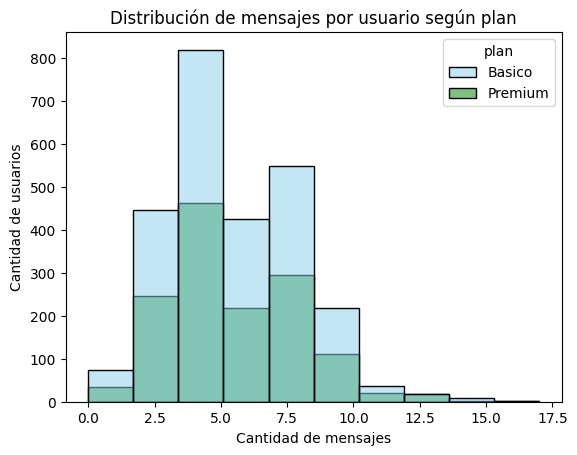

In [74]:
# Histograma para visualizar la cantidad de mensajes según el plan
sns.histplot(
    data=user_profile,
    x="total_texts",
    hue="plan",
    bins=10,
    palette=["skyblue", "green"]
)

plt.title("Distribución de mensajes por usuario según plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Predominio del plan Básico: se observa una mayor cantidad de usuarios Básicos en la mayoría de los rangos de mensajes. Esto puede estar relacionado con que hay más usuarios en este plan, por lo que no significa necesariamente que consuman más mensajes individualmente.
- Patrón de consumo similar: en ambos planes, la mayor concentración de usuarios se encuentra aproximadamente entre 3 y 8 mensajes, con un pico cercano a 4–5 mensajes por usuario.
- Usuarios de alto consumo: hay pocos usuarios que envían más de 10 mensajes, y algunos alcanzan aproximadamente 15–17 mensajes. Estos casos podrían representar oportunidades para ofrecer planes con mayor capacidad.
- Oportunidad comercial: ConnectaTel podría analizar si los usuarios que envían más mensajes tienen el plan adecuado o si podrían beneficiarse de una oferta Premium.
Conclusión: ambos planes muestran una concentración de usuarios en niveles moderados de mensajería y una pequeña proporción con consumo elevado. Para comparar cuál plan tiene un mayor consumo relativo, sería conveniente analizar los porcentajes dentro de cada plan, en lugar de comparar únicamente el número de usuarios. 

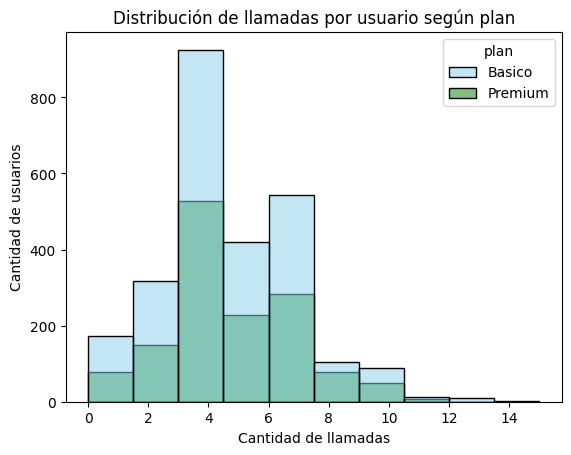

In [75]:

# Histograma para visualizar la cantidad de llamadas según el plan
sns.histplot(
    data=user_profile,
    x="total_calls",
    hue="plan",
    bins=10,
    palette=["skyblue", "green"]
)

plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de llamadas por usuario según plan")

plt.show()




💡 Insights: Distribución de llamadas por usuario
Predominio del plan Básico: se observa una mayor cantidad de usuarios Básicos en casi todos los rangos de llamadas. Esto puede deberse a que hay más usuarios con este plan, por lo que no significa necesariamente que realicen más llamadas individualmente.
Patrón de consumo similar: ambos planes presentan su mayor concentración alrededor de 3–4 llamadas por usuario. La mayoría realiza aproximadamente entre 2 y 7 llamadas.
Usuarios de alto consumo: hay pocos usuarios que realizan más de 10 llamadas, con algunos casos que llegan aproximadamente a 15. Estos usuarios podrían tener necesidades de comunicación superiores al promedio.
Oportunidad comercial: ConnectaTel podría revisar si los usuarios con mayor cantidad de llamadas tienen suficiente capacidad en su plan actual y evaluar ofertas adaptadas a su consumo.

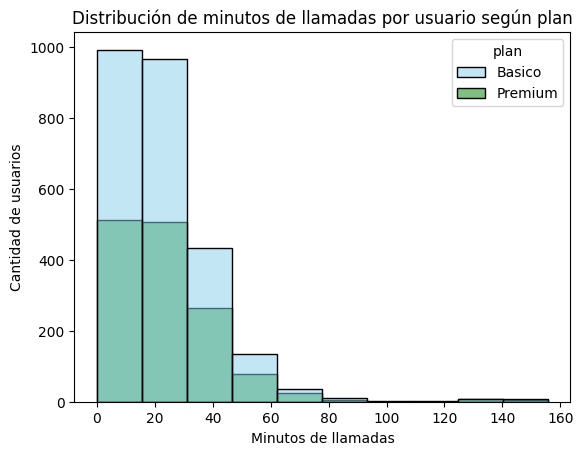

In [77]:
# Histograma para visualizar los minutos de llamadas según el plan
sns.histplot(
    data=user_profile,
    x="total_duration",
    hue="plan",
    bins=10,
    palette=["skyblue", "green"]
)

plt.xlabel("Minutos de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de minutos de llamadas por usuario según plan")

plt.show()

💡 Insights: Distribución de minutos de llamadas por usuario
- Mayor concentración: la mayoría de los usuarios acumula aproximadamente entre 0 y 40 minutos de llamadas. Los intervalos de 0–15 y 15–30 minutos presentan las frecuencias más altas.
- Distribución asimétrica: el histograma muestra una cola hacia la derecha; a medida que aumentan los minutos de llamadas, disminuye la cantidad de usuarios.
- Posibles valores atípicos: se observan pocos usuarios con consumos superiores a 100 minutos, algunos cercanos a 150–155 minutos. Conviene revisar estos casos, aunque no necesariamente son errores.
- Oportunidad comercial: analizar el consumo de minutos según el plan contratado puede ayudar a identificar usuarios que podrían necesitar más minutos o un plan diferente.
Conclusión: el consumo de llamadas se concentra en duraciones relativamente bajas, mientras que un grupo pequeño de usuarios utiliza muchos más minutos que el resto. Esta diferencia puede ser útil para segmentar clientes y evaluar si sus planes actuales se ajustan a sus necesidades

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

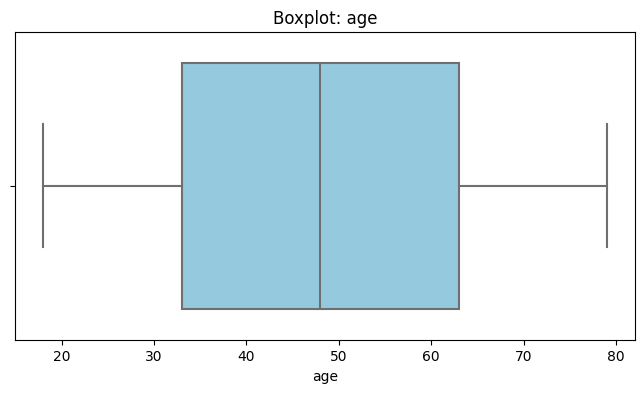

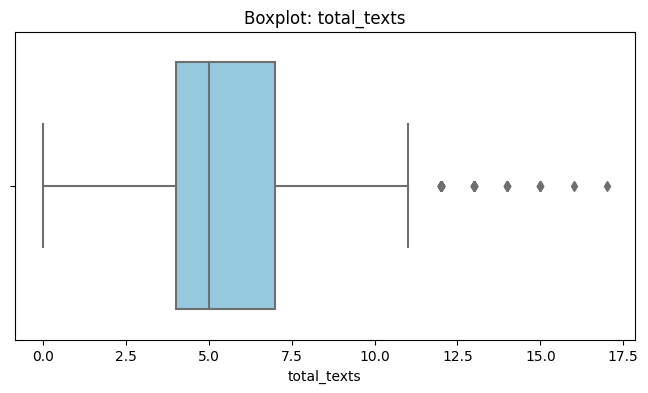

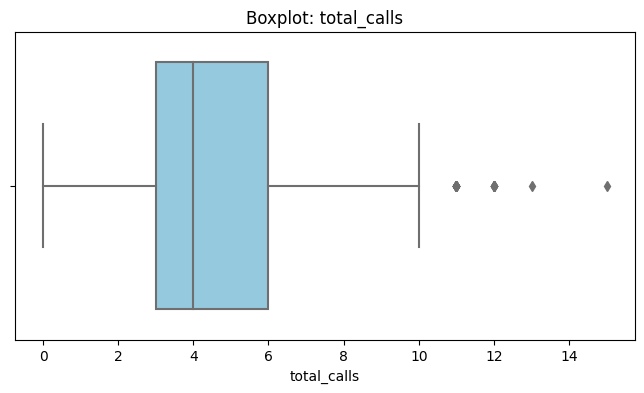

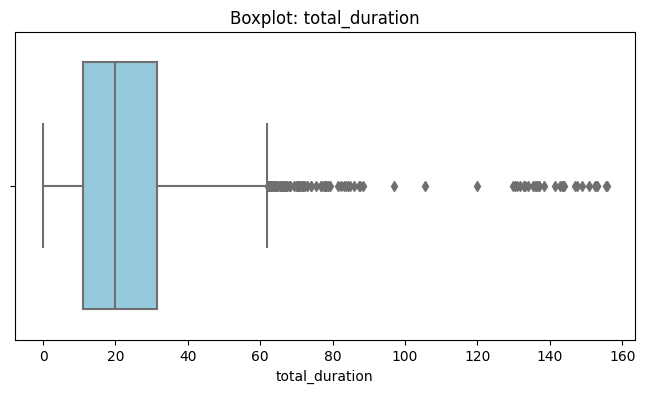

In [78]:
# Visualizando usando BoxPlot
columnas_numericas = [
    'age',
    'total_texts',
    'total_calls',
    'total_duration'
]

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()



💡Insights: 
- Age: La distribución de edades presenta una mediana aproximada de 48 años. La mayoría de los usuarios se encuentra entre los 33 y 63 años. No presenta outliers visibles, ya que no se observan puntos fuera de los bigotes del boxplot.
 
- cant_mensajes: Total de mensajes (total_texts): La mediana es de aproximadamente 5 mensajes por usuario. La mayoría de los usuarios envía entre 4 y 7 mensajes.
Outliers: Sí presenta valores atípicos. Se observan usuarios que envían entre 12 y 17 mensajes, por encima del bigote superior.
Interpretación: La mayoría tiene un consumo moderado de mensajes, mientras que un grupo pequeño presenta un uso más elevado. Estos usuarios podrían analizarse para identificar patrones de consumo o posibles oportunidades comerciales.


- cant_llamadas: total de llamadas (total_calls): La mediana es de aproximadamente 4 llamadas por usuario. La mayoría de los usuarios realiza entre 3 y 6 llamadas.
Outliers: Sí presenta valores atípicos. Se observan algunos usuarios con aproximadamente 11, 12, 13 y 15 llamadas, por encima del bigote superior.
Interpretación: La mayoría de los usuarios realiza una cantidad moderada de llamadas, mientras que un grupo pequeño tiene un consumo elevado. Estos usuarios podrían analizarse para identificar patrones de uso y posibles oportunidades comerciales.


- cant_minutos_llamada: Duración total de llamadas (total_duration): La mediana es de aproximadamente 21 minutos por usuario. La mayoría de los usuarios acumula entre 11 y 31 minutos de llamadas.
Outliers: Sí presenta numerosos valores atípicos por encima del bigote superior, con algunos usuarios que superan los 100 minutos y llegan aproximadamente a 155 minutos.
Interpretación: La mayoría de los usuarios tiene un consumo moderado de minutos, mientras que un grupo pequeño registra duraciones mucho más altas. Estos casos pueden ser útiles para identificar patrones de consumo y evaluar si los planes contratados se ajustan a las necesidades de los usuarios.

In [79]:

# Calcular límites con el método IQR
columnas_limites = ['age', 'total_texts', 'total_calls', 'total_duration']

# Verificar que las columnas existen en user_profile
print(columnas_limites)
print(user_profile[columnas_limites].head())

['age', 'total_texts', 'total_calls', 'total_duration']
    age  total_texts  total_calls  total_duration
0  38.0          7.0          3.0           23.70
1  53.0          5.0         10.0           33.18
2  57.0          5.0          2.0           10.74
3  69.0         11.0          3.0            8.99
4  63.0          4.0          3.0            8.01


In [58]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,total_texts,total_calls,total_duration
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?
  
1. cant_mensajes — Mantener los outliers.

La cantidad máxima es de 17 mensajes por usuario, mientras que la mediana es de 5. Aunque algunos usuarios envían muchos más mensajes que la mayoría, este comportamiento puede ser real y útil para identificar clientes con un mayor consumo del servicio. No los eliminaría sin comprobar primero si existen errores en los datos.

2. cant_llamadas — Mantener los outliers.

El máximo es de 15 llamadas por usuario y la mediana es de 4. Los usuarios que realizan más llamadas podrían tener necesidades de comunicación diferentes a las del resto. Mantendría estos registros porque pueden representar patrones reales de consumo y ser relevantes para las estrategias comerciales.

3. cant_minutos_llamada — Mantener los outliers, pero revisarlos.

La mediana es de aproximadamente 19,78 minutos, mientras que el máximo alcanza los 155,69 minutos. Existe una diferencia considerable, por lo que estos valores deben revisarse para confirmar que sean correctos. Sin embargo, un usuario puede acumular muchos minutos de llamadas legítimamente, por lo que no los eliminaría automáticamente.

Conclusión general
Mantendría los outliers de las tres variables porque representan posibles comportamientos reales de los usuarios y pueden aportar información comercial valiosa. Antes de tomar una decisión definitiva, revisaría los valores extremos para identificar posibles errores de registro. Si se confirma que son válidos, los conservaría y utilizaría medidas robustas, como la mediana, para evitar que influyan excesivamente en los análisis.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [80]:

# Crear columna grupo_uso
user_profile["grupo_uso"] = np.where(
    (user_profile["total_calls"] < 5) & (user_profile["total_texts"] < 5),
    "Bajo uso",
    np.where(
        (user_profile["total_calls"] < 10) & (user_profile["total_texts"] < 10),
        "Uso medio",
        "Alto uso"
    )
)

# Verificar la distribución de los grupos
print(user_profile["grupo_uso"].value_counts())

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64


In [81]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,total_texts,total_calls,total_duration,total_length,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,258.0,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,226.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,225.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,530.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,229.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [82]:
# Crear columna grupo_edad
user_profile["grupo_edad"] = np.where(
    user_profile["age"] < 30,
    "Joven",
    np.where(
        user_profile["age"] < 60,
        "Adulto",
        "Adulto Mayor"
    )
)

# Verificar los resultados
print(user_profile["grupo_edad"].value_counts())


Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [83]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,total_texts,total_calls,total_duration,total_length,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,258.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,226.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,225.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,530.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,229.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

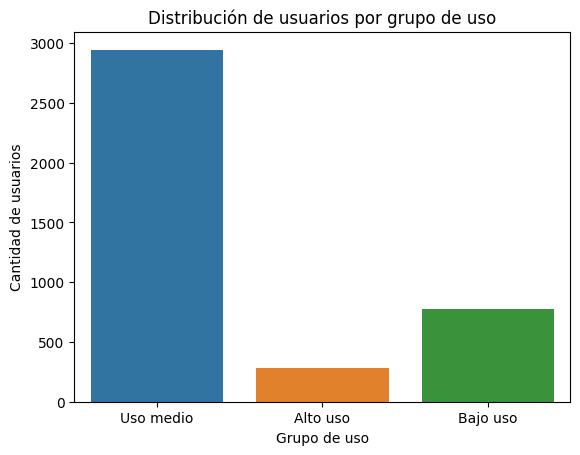

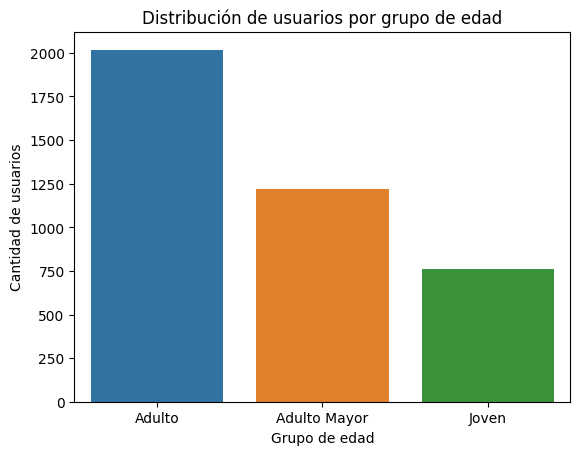

In [84]:

# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso")
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad")
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()


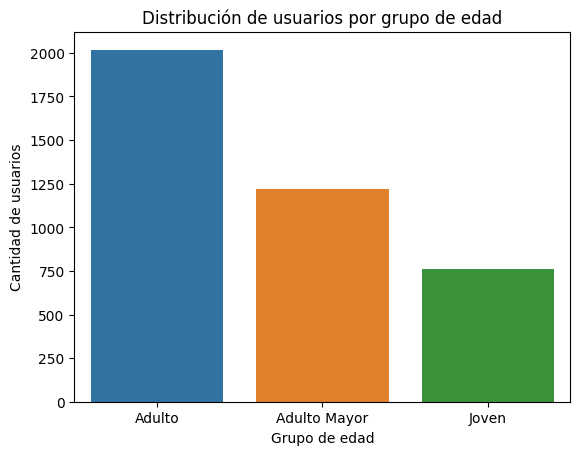

In [85]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad")

plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

Se identificó valores faltantes, un valor centinela en la edad (-999) y variables que requerían revisión.
- Ciudad (city): 469 valores faltantes de 4.000 usuarios, equivalentes al 11,73 %.
- Fecha de cancelación (churn_date): 3.534 valores faltantes (88,35 %). Estos podrían representar usuarios que no han cancelado el servicio, por lo que no deben imputarse automáticamente.
- Fecha de uso (date): 50 valores faltantes de 40.000 registros (0,125 %).
- Duración (duration): 22.076 valores faltantes (55,19 %).
- Longitud (length): 17.896 valores faltantes (44,74 %).
- Edad (age): se detectó el valor centinela -999, que no representa una edad válida y debio corregirse.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
Se crearon dos tipos de segmentación.

Por edad:
- Joven: menores de 30 años.
- Adulto: desde los 30 hasta antes de los 60 años.
- Adulto Mayor: 60 años o más.
El análisis muestra usuarios aproximadamente entre los 18 y 79 años, con una mediana cercana a los 48 años. La distribución es relativamente uniforme, sin un único grupo de edad claramente dominante.

Por nivel de uso:
- Bajo uso: menos de 5 llamadas y menos de 5 mensajes.
- Uso medio: menos de 10 llamadas y menos de 10 mensajes, siempre que no pertenezcan al grupo de bajo uso.
- Alto uso: los demás casos.
- 
Los histogramas muestran que el consumo se concentra principalmente en niveles moderados. La mediana es de aproximadamente 5 mensajes y 4 llamadas por usuario. También existen usuarios con un consumo considerablemente superior.

Los gráficos por plan muestran que hay más usuarios del plan Básico. Sin embargo, para determinar qué plan tiene un consumo proporcionalmente mayor, sería necesario comparar las distribuciones normalizadas o los promedios por plan.

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

Los usuarios de alto uso son un segmento importante para investigar, porque podrían necesitar más mensajes o minutos que los incluidos en sus planes actuales. Una oferta adaptada a ese consumo podría mejorar su satisfacción y favorecer la permanencia.

Los usuarios de uso medio también representan una oportunidad comercial, ya que podrían beneficiarse de planes flexibles que se ajusten a sus hábitos.

Por otro lado, los usuarios de bajo uso podrían estar interesados en opciones más económicas o con menos capacidad incluida.

Aunque los usuarios de alto uso son candidatos relevantes para estrategias comerciales, no podemos afirmar que sean los más rentables sin analizar sus ingresos, costes y cancelaciones.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Los boxplots permitieron identificar posibles valores atípicos en las variables de consumo:
- Mensajes (total_texts): la mediana es de aproximadamente 5 mensajes, pero algunos usuarios llegan a enviar entre 12 y 17.
- Llamadas (total_calls): la mediana es de aproximadamente 4 llamadas, mientras que algunos usuarios realizan entre 11 y 15.
- Minutos (total_duration): la mediana es de aproximadamente 19,78 minutos. Se observan usuarios que superan los 100 minutos y llegan aproximadamente a 155,69 minutos.
- Edad (age): el boxplot no muestra valores atípicos visibles.
Estos valores extremos no necesariamente son errores. Pueden representar clientes con necesidades de comunicación superiores al promedio.

Implicación comercial: ConnectaTel podría identificar a los usuarios con mayor consumo y evaluar si sus planes actuales cubren adecuadamente sus necesidades. Antes de eliminar un valor atípico, debe comprobarse que sea un error y no un comportamiento real.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

1. Evaluar un plan de alto consumo.
Considerar una opción con más mensajes y minutos para los usuarios que presentan un consumo elevado de forma recurrente. La decisión debe basarse en la demanda observada y en la rentabilidad esperada.

2. Ofrecer alternativas flexibles para usuarios de bajo consumo.
Evaluar un plan más económico o con una capacidad menor para quienes utilizan pocos mensajes y minutos. Esto podría mejorar la percepción de valor y ayudar a reducir cancelaciones.

3. Personalizar las campañas según el comportamiento.
Combinar edad, plan contratado y nivel de uso para identificar necesidades concretas. La edad debe utilizarse como variable complementaria, no como único criterio para ofrecer un producto.

4. Investigar la relación entre consumo y cancelación.
Analizar si los usuarios de alto consumo o los de bajo consumo presentan diferentes tasas de cancelación. Esto ayudaría a diseñar campañas de retención más efectivas.

5. Mejorar la calidad de los datos.
Mantener controles para detectar edades inválidas, fechas sospechosas y valores faltantes. También es importante conservar los faltantes estructurales de duration y length cuando esas variables no correspondan al tipo de uso.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- abc
- abc


🔍 **Segmentos por Edad**
- abc
- abc 


📊 **Segmentos por Nivel de Uso**
- abc
- abc


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- abc
- abc 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`